# Flight dataset: column inventory and categories

Dataset: `flights_2008_2025_cleaned.parquet`  
Rows: **114,362,496** | Stored fields: **37**

The groups below distinguish variables known before departure from fields created during or after the flight. This matters because using a field that is unavailable at prediction time causes **target leakage**.

| Category                                 | Columns                                                                                                                                                                                               |
|------------------------------------------|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Calendar                                 | `year`, `month`, `day`, `formatted_date`, `dayofweek`                                                                                                                                                 |
| Scheduled flight information             | `airline`, `iata_code_reporting_airline`, `flight_number`, `tail_number`, `origin_airport_id`, `dest_airport_id`, `crs_dep_time_hhmm`, `scheduled_arrival_hhmm`, `scheduled_elapsed_time`, `distance` |
| Realized departure operations            | `departure_time_hhmm`, `departure_delay`, `departure_delay_mins`, `taxi_out`, `wheels_off_hhmm`                                                                                                       |
| Realized flight/arrival operations       | `elapsed_time`, `air_time`, `wheels_on_hhmm`, `taxi_in`, `arrival_time_hhmm`                                                                                                                          |
| Primary outcomes / possible targets      | `arrival_delay`, `arrival_delay_mins`, `cancelled`, `diverted`                                                                                                                                        |
| Disruption details and delay attribution | `cancellation_code`, `airline_delay`, `weather_delay`, `air_system_delay`, `security_delay`, `late_aircraft_delay`, `div_reached_dest`, `div_actual_elapsed_time`                                     |

In [63]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay,
)
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_FRACTION = 0.0005  # 0.05%
DATA_PATH = "datasets/USDOT_1987_2025_Flights_Dataset/flights_2008_2025_cleaned.parquet"
features = ["arrival_delay", "origin_airport_id","dest_airport_id", "airline", "distance", "month"]

In [ ]:
COLUMN_CATEGORIES = {
    "calendar": [
        "year", "month", "day", "formatted_date", "dayofweek",
    ],
    "scheduled_flight_information": [
        "airline", "iata_code_reporting_airline", "flight_number", "tail_number",
        "origin_airport_id", "dest_airport_id", "crs_dep_time_hhmm",
        "scheduled_arrival_hhmm", "scheduled_elapsed_time", "distance",
    ],
    "realized_departure_operations": [
        "departure_time_hhmm", "departure_delay", "departure_delay_mins",
        "taxi_out", "wheels_off_hhmm",
    ],
    "realized_flight_arrival_operations": [
        "elapsed_time", "air_time", "wheels_on_hhmm", "taxi_in",
        "arrival_time_hhmm",
    ],
    "outcomes_possible_targets": [
        "arrival_delay", "arrival_delay_mins", "cancelled", "diverted",
    ],
    "disruption_details_delay_attribution": [
        "cancellation_code", "airline_delay", "weather_delay",
        "air_system_delay", "security_delay", "late_aircraft_delay",
        "div_reached_dest", "div_actual_elapsed_time",
    ],
    "technical_metadata": ["__index_level_0__"],
}

parquet = pq.ParquetFile(DATA_PATH)


## Reproducible 0.05% sample

The following cell uses `SEED = 42` and `SAMPLE_FRACTION = 0.0005`. It samples row positions without loading the full 114-million-row dataset into memory, then reads only the selected columns from the affected row groups.

In [65]:
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))
columns = features + ["air_time", "cancelled", "diverted"]

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group, columns=columns)
        parts.append(table.take(rows).to_pandas())
    offset = end
sample = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(sample):,} flights")

Sample: 57,181 flights


## Distribution of arrival delays

`arrival_delay` is signed: negative values mean the flight arrived early, `0` means on time, and positive values mean it arrived late. 
To keep extreme outliers from compressing the chart, the histogram displays the central 98% of valid sampled delays. 

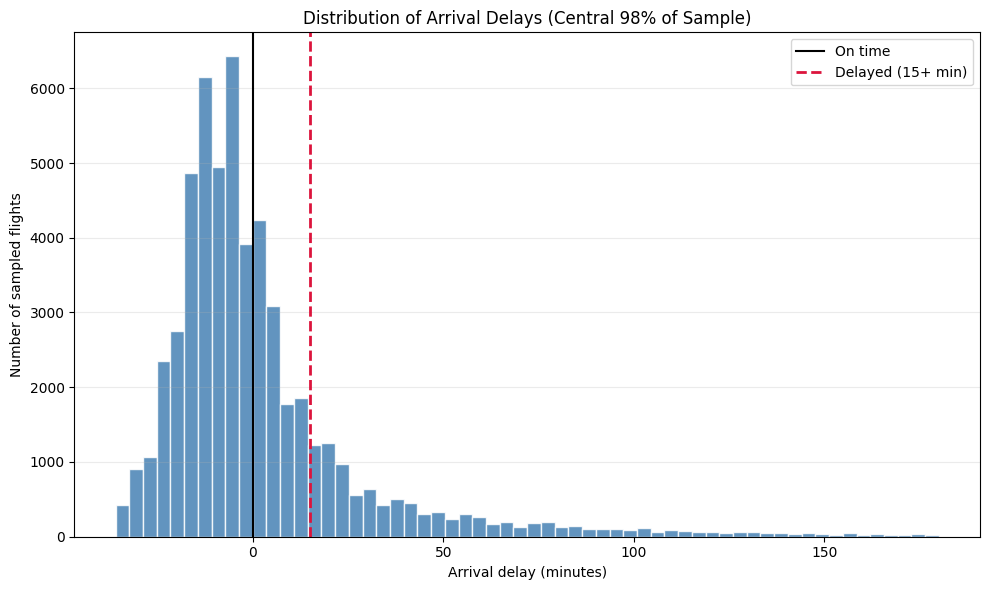

Valid completed flights: 55,980
Median arrival delay: -5.0 minutes
Flights delayed 15+ minutes: 19.1%
Displayed range (1st-99th percentile): -36.0 to 180.0 minutes


In [67]:
valid_arrivals = sample.loc[
    (~sample["cancelled"])
    & (~sample["diverted"])
    & sample["arrival_delay"].notna(),
    "arrival_delay",
]

lower_bound, upper_bound = valid_arrivals.quantile([0.01, 0.99])
display_delays = valid_arrivals[valid_arrivals.between(lower_bound, upper_bound)]
delayed_rate = valid_arrivals.ge(15).mean()

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(display_delays, bins=60, color="steelblue", edgecolor="white", alpha=0.85)
ax.axvline(0, color="black", linewidth=1.5, label="On time")
ax.axvline(15, color="crimson", linestyle="--", linewidth=2, label="Delayed (15+ min)")
ax.set(
    title="Distribution of Arrival Delays (Central 98% of Sample)",
    xlabel="Arrival delay (minutes)",
    ylabel="Number of sampled flights",
)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Valid completed flights: {len(valid_arrivals):,}")
print(f"Median arrival delay: {valid_arrivals.median():.1f} minutes")
print(f"Flights delayed 15+ minutes: {delayed_rate:.1%}")
print(f"Displayed range (1st-99th percentile): {lower_bound:.1f} to {upper_bound:.1f} minutes")

In [68]:
airports = pd.concat(
    [sample["origin_airport_id"], sample["dest_airport_id"]],
    ignore_index=True,
).dropna().unique()

print(f"{len(airports):,} unique airports")

384 unique airports


In [69]:
airport_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airports.csv')

In [70]:
airport_df = airport_df[['airport_id', 'airport_code']]
airport_df.head()

,airport_id,airport_code
0,12953,LGA
1,13871,OMA
2,13851,OKC
3,11481,ECP
4,12951,LFT


In [71]:
airport_dict = (
    airport_df
    .set_index("airport_id")["airport_code"]
    .to_dict()
)

In [72]:
sample['origin_airport'] = sample['origin_airport_id'].map(airport_dict)
sample['dest_airport'] = sample['dest_airport_id'].map(airport_dict)

In [73]:
sample['route'] = sample['origin_airport'].astype(str) + '-' + sample['dest_airport'].astype(str)

In [74]:
sample.head()

,arrival_delay,origin_airport_id,dest_airport_id,airline,distance,month,air_time,cancelled,diverted,origin_airport,dest_airport,route
0,-9.0,15249,10397,9E,223.0,7,42.0,False,False,TLH,ATL,TLH-ATL
1,-18.0,10397,13198,9E,692.0,7,96.0,False,False,ATL,MCI,ATL-MCI
2,-12.0,13487,11898,9E,284.0,7,46.0,False,False,MSP,GFK,MSP-GFK
3,-8.0,11775,13487,9E,197.0,7,39.0,False,False,FSD,MSP,FSD-MSP
4,6.0,11433,14711,9E,300.0,7,52.0,False,False,DTW,SCE,DTW-SCE


## Percentage of flights delayed by airport

The chart below groups completed, non-diverted flights by **origin airport** and shows the percentage arriving at least **15 minutes late**. This lets us compare the delay risk associated with where a flight departs and matches the binary outcome that will be used for logistic regression. 

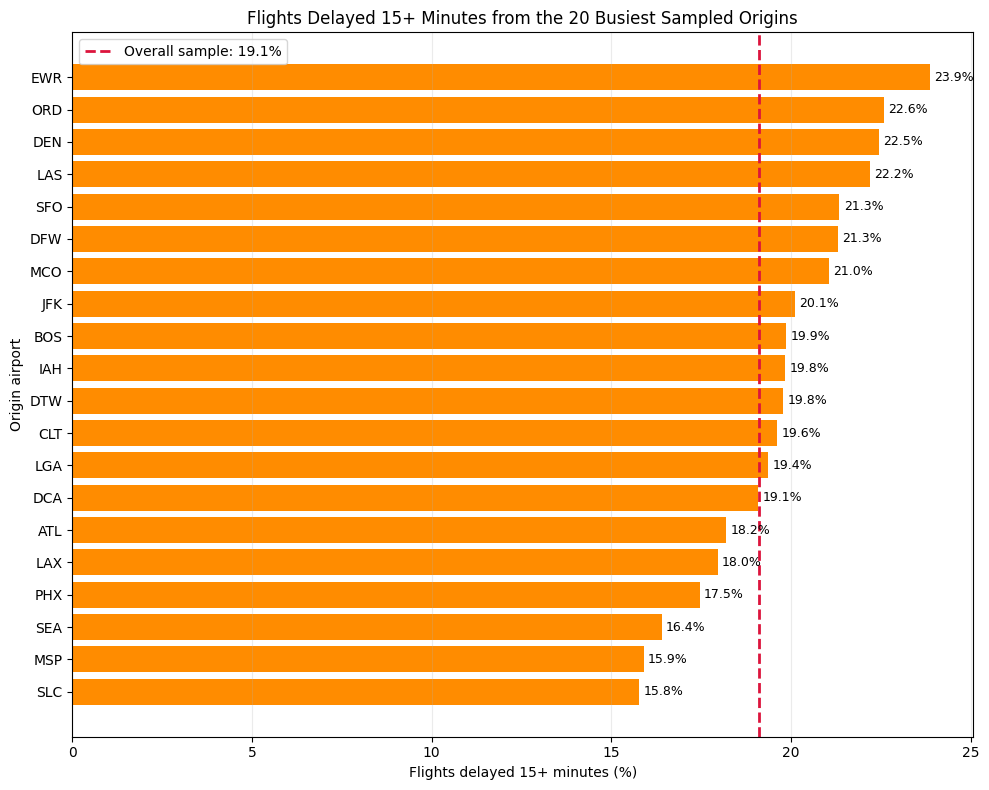

,origin_airport,flight_count,delayed_rate
0,EWR,993,23.9%
1,ORD,2595,22.6%
2,DEN,2129,22.5%
3,LAS,1438,22.2%
4,SFO,1251,21.3%
5,DFW,2323,21.3%
6,MCO,1093,21.0%
7,JFK,975,20.1%
8,BOS,1022,19.9%
9,IAH,1351,19.8%


In [75]:
AIRPORT_COLUMN = "origin_airport"
N_AIRPORTS = 20
airport_role = "Origin"
busiest_origin_airports = (
    sample[AIRPORT_COLUMN].dropna().value_counts().head(N_AIRPORTS).index.tolist()
)

valid_airport_arrivals = sample.loc[
    (~sample["cancelled"])
    & (~sample["diverted"])
    & sample["arrival_delay"].notna()
    & sample[AIRPORT_COLUMN].notna(),
    [AIRPORT_COLUMN, "arrival_delay"],
].copy()
overall_delayed_rate = valid_airport_arrivals["arrival_delay"].ge(15).mean()

airport_delay_rates = (
    valid_airport_arrivals
    .groupby(AIRPORT_COLUMN, as_index=False)
    .agg(
        flight_count=("arrival_delay", "size"),
        delayed_rate=("arrival_delay", lambda values: values.ge(15).mean()),
    )
)

busiest_airport_delay_rates = (
    airport_delay_rates.loc[
        airport_delay_rates[AIRPORT_COLUMN].isin(busiest_origin_airports)
    ]
    .sort_values("delayed_rate")
    .assign(delayed_percent=lambda frame: frame["delayed_rate"] * 100)
)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(
    busiest_airport_delay_rates[AIRPORT_COLUMN],
    busiest_airport_delay_rates["delayed_percent"],
    color="darkorange",
)
ax.axvline(
    overall_delayed_rate * 100,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Overall sample: {overall_delayed_rate:.1%}",
)
ax.set(
    title=f"Flights Delayed 15+ Minutes from the {N_AIRPORTS} Busiest Sampled Origins",
    xlabel="Flights delayed 15+ minutes (%)",
    ylabel=f"{airport_role} airport",
)
ax.grid(axis="x", alpha=0.25)
ax.legend()
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
plt.tight_layout()
plt.show()

display(
    busiest_airport_delay_rates.sort_values("delayed_rate", ascending=False)
    .assign(delayed_rate=lambda frame: frame["delayed_rate"].map("{:.1%}".format))
    .drop(columns="delayed_percent")
    .reset_index(drop=True)
)

## Restrict the modeling sample to the 20 busiest origins

For the Logistic Model we will use just the 20 busiest airports 

In [76]:
model_sample = sample.loc[
    sample["origin_airport"].isin(busiest_origin_airports)
].copy()

retained_rate = len(model_sample) / len(sample)
print(f"Original sample: {len(sample):,} flights")
print(f"Filtered modeling sample: {len(model_sample):,} flights ({retained_rate:.1%} retained)")
print(f"Origin airports retained: {model_sample['origin_airport'].nunique()}")
display(
    model_sample["origin_airport"]
    .value_counts()
    .rename_axis("origin_airport")
    .reset_index(name="sampled_flights")
)

Original sample: 57,181 flights
Filtered modeling sample: 30,230 flights (52.9% retained)
Origin airports retained: 20


,origin_airport,sampled_flights
0,ATL,3326
1,ORD,2689
2,DFW,2379
3,DEN,2166
4,LAX,1786
5,PHX,1618
6,LAS,1462
7,CLT,1403
8,IAH,1373
9,SFO,1281


## Binary delay target

For the logistic-regression outcome, `delayed_over_15` equals `1` when a completed, non-diverted flight arrived **more than 15 minutes late**, and `0` otherwise. Cancelled flights, diverted flights, and rows without an arrival delay are removed.

In [ ]:
TARGET = "delayed_over_15"

model_sample = model_sample.loc[
    (~model_sample["cancelled"])
    & (~model_sample["diverted"])
    & model_sample["arrival_delay"].notna()
].copy()

model_sample[TARGET] = (model_sample["arrival_delay"]>15).astype("int8")

target_summary = (
    model_sample[TARGET]
    .value_counts()
    .sort_index()
    .rename_axis(TARGET)
    .reset_index(name="flights")
)
target_summary["percentage"] = (
    target_summary["flights"] / target_summary["flights"].sum() * 100
).round(1)

display(target_summary)
print(f"Modeling rows: {len(model_sample):,}")
print(f"Delayed more than 15 minutes: {model_sample[TARGET].mean():.1%}")

,delayed_over_15,flights,percentage
0,0,23979,81.0
1,1,5636,19.0


Modeling rows: 29,615
Delayed more than 15 minutes: 19.0%


## Class-balance strategy

The target is imbalanced, but balancing the entire dataset before the train/test split would make the test set unrealistic. To achieve this we will seperate the test and train set first before undersampling the training set

In [78]:
model_sample_unbalanced = model_sample.copy()
natural_class_summary = (
    model_sample_unbalanced[TARGET]
    .value_counts()
    .sort_index()
    .rename_axis(TARGET)
    .reset_index(name="flights")
)
natural_class_summary["percentage"] = (
    natural_class_summary["flights"]
    / natural_class_summary["flights"].sum()
    * 100
).round(1)
display(natural_class_summary)

,delayed_over_15,flights,percentage
0,0,23979,81.0
1,1,5636,19.0


## Independent variables and train/test split

The split is stratified so the 80% training and 20% test partitions retain the natural delay proportion. Only the training partition is then balanced by reproducibly undersampling its majority class with `SEED = 42`.

In [79]:
numeric_features = ["distance"]
categorical_features = ["airline", "month", "origin_airport"]
independent_variables = numeric_features + categorical_features

X = model_sample_unbalanced[independent_variables].copy()
y = model_sample_unbalanced[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

train_data = X_train.copy()
train_data[TARGET] = y_train
training_rows_per_class = int(train_data[TARGET].value_counts().min())
balanced_train_data = (
    train_data
    .groupby(TARGET, group_keys=False)
    .sample(n=training_rows_per_class, random_state=SEED)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)
X_train_balanced = balanced_train_data[independent_variables]
y_train_balanced = balanced_train_data[TARGET]

split_summary = pd.DataFrame(
    {
        "dataset": ["Training before balancing", "Training after balancing", "Test (unchanged)"],
        "rows": [len(y_train), len(y_train_balanced), len(y_test)],
        "delayed_rate": [y_train.mean(), y_train_balanced.mean(), y_test.mean()],
    }
)
split_summary["delayed_rate"] = split_summary["delayed_rate"].map("{:.1%}".format)
display(split_summary)

,dataset,rows,delayed_rate
0,Training before balancing,23692,19.0%
1,Training after balancing,9018,50.0%
2,Test (unchanged),5923,19.0%


## Standardization and categorical encoding

We standardize the continuous `distance` feature with scikit-learn's `StandardScaler`, which applies the z-score transformation:

$$z = \frac{x - \mu_{train}}{\sigma_{train}}$$

This centers training distances near 0 with a standard deviation near 1

`airline`, `month`, and `origin_airport` are one-hot encoded together because their labels do not represent a continuous scale. The resulting binary indicator columns are not standardized because their 0/1 interpretation is already meaningful.

In [80]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric_zscore", StandardScaler(), numeric_features),
        ("categorical_onehot", OneHotEncoder(drop="first"), categorical_features),
    ],
    remainder="drop",
)

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1_000, random_state=SEED)),
    ]
)
logistic_model.fit(X_train_balanced, y_train_balanced)

distance_scaler = (logistic_model.named_steps["preprocessor"].named_transformers_["numeric_zscore"])
scaled_training_distance = distance_scaler.transform(X_train_balanced[numeric_features]).ravel()

standardization_summary = pd.DataFrame(
    {
        "feature": numeric_features,
        "training_mean_used": distance_scaler.mean_,
        "training_std_used": distance_scaler.scale_,
        "scaled_mean": [scaled_training_distance.mean()],
        "scaled_std": [scaled_training_distance.std(ddof=0)],
    }
)
display(standardization_summary.round(3))

,feature,training_mean_used,training_std_used,scaled_mean,scaled_std
0,distance,871.938,622.739,-0.0,1.0


## Baseline logistic-regression performance

We will report Accuracy, precision, recall, F1 score, and ROC AUC.

,metric,value
0,Accuracy,0.532
1,Precision,0.224
2,Recall,0.592
3,F1 score,0.325
4,ROC AUC,0.572


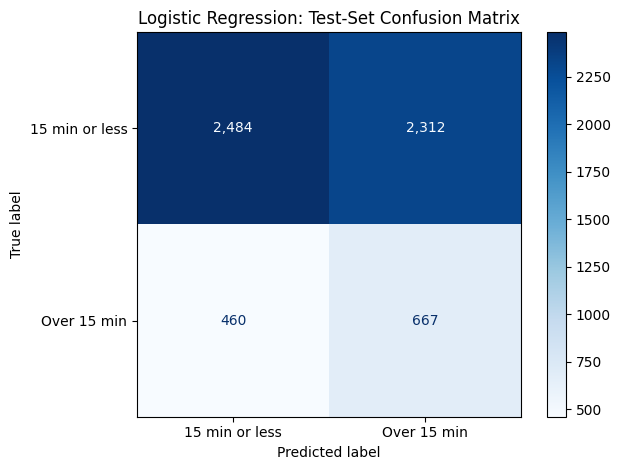

In [81]:
y_pred = logistic_model.predict(X_test)
y_probability = logistic_model.predict_proba(X_test)[:, 1]

model_metrics = pd.DataFrame(
    {
        "metric": ["Accuracy", "Precision", "Recall", "F1 score", "ROC AUC"],
        "value": [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred, zero_division=0),
            recall_score(y_test, y_pred, zero_division=0),
            f1_score(y_test, y_pred, zero_division=0),
            roc_auc_score(y_test, y_probability),
        ],
    }
)
display(model_metrics.style.format({"value": "{:.3f}"}))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["15 min or less", "Over 15 min"],
    cmap="Blues",
    values_format=",",
)
plt.title("Logistic Regression: Test-Set Confusion Matrix")
plt.tight_layout()
plt.show()

## Conclusion

- **Accuracy (0.532):** the model classified 53.2% of all test flights correctly. Because about 81% of flights are not delayed, accuracy is misleading here and is below the simple strategy of always predicting the majority class. I suspect this occured due to undersampling the training data to balance the classes.
- **Precision (0.224):** among flights predicted to be delayed, 22.4% were actually delayed. This means there were many false delay alarms.
- **Recall (0.592):** the model identified 59.2% of the flights that were actually delayed. This means the model succesfull predicted correctly flights that were delayed 59.2% of the time.
- **F1 score (0.325):** This shows that the balance between detecting delays and avoiding false alarms is weak.
- **ROC AUC (0.572):** the model has only a modest ability to rank delayed flights above non-delayed flights. `0.50` represents random ranking and `1.00` represents perfect ranking.

The confusion matrix contains **2,484 true negatives** (correctly predicted as 15 minutes or less), **2,312 false positives** (false delay alarms), **460 false negatives** (delays the model missed), and **667 true positives** (delays correctly detected).

The current model detects nearly 60% of actual delays, but its low precision and ROC AUC show that `distance`, `airline`, `month`, and `origin_airport` alone do not separate the classes well. Scheduled departure time, day of week, scheduled duration, and origin-airport weather conditons dould be promising additions for the next model.

## Logistic-regression coefficients

,categorical_feature,reference_category
0,airline,9E
1,month,1.0
2,origin_airport,ATL


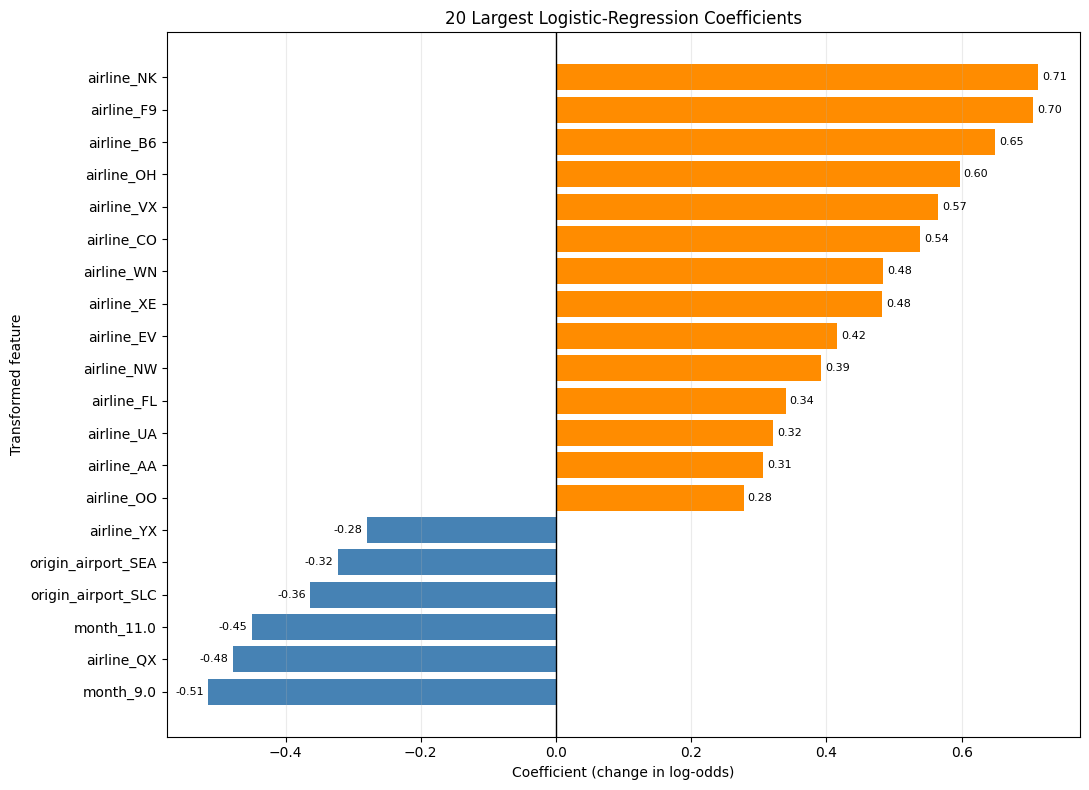

,feature,coefficient,odds_ratio
0,airline_NK,0.714,2.041
1,airline_F9,0.705,2.024
2,airline_B6,0.649,1.914
3,airline_OH,0.597,1.816
4,airline_VX,0.565,1.760
5,airline_CO,0.538,1.713
6,airline_WN,0.484,1.623
7,airline_XE,0.482,1.619
8,airline_EV,0.415,1.514
9,airline_NW,0.392,1.480


In [82]:
fitted_preprocessor = logistic_model.named_steps["preprocessor"]
fitted_classifier = logistic_model.named_steps["classifier"]

feature_names = pd.Series(
    fitted_preprocessor.get_feature_names_out(),
    name="feature",
)
feature_names = (
    feature_names
    .str.replace("numeric_zscore__", "", regex=False)
    .str.replace("categorical_onehot__", "", regex=False)
    .replace({"distance": "distance (1 SD)"})
)

coefficient_table = pd.DataFrame(
    {
        "feature": feature_names,
        "coefficient": fitted_classifier.coef_.ravel(),
    }
)
coefficient_table["odds_ratio"] = np.exp(coefficient_table["coefficient"])
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()

categorical_encoder = fitted_preprocessor.named_transformers_["categorical_onehot"]
reference_categories = pd.DataFrame(
    {
        "categorical_feature": categorical_features,
        "reference_category": [
            categories[0] for categories in categorical_encoder.categories_
        ],
    }
)
display(reference_categories)

N_COEFFICIENTS = 20
plot_coefficients = (
    coefficient_table
    .nlargest(N_COEFFICIENTS, "absolute_coefficient")
    .sort_values("coefficient")
)
colors = np.where(
    plot_coefficients["coefficient"] >= 0,
    "darkorange",
    "steelblue",
)

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(
    plot_coefficients["feature"],
    plot_coefficients["coefficient"],
    color=colors,
)
ax.axvline(0, color="black", linewidth=1)
ax.set(
    title=f"{N_COEFFICIENTS} Largest Logistic-Regression Coefficients",
    xlabel="Coefficient (change in log-odds)",
    ylabel="Transformed feature",
)
ax.grid(axis="x", alpha=0.25)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

display(
    plot_coefficients[["feature", "coefficient", "odds_ratio"]]
    .sort_values("coefficient", ascending=False)
    .reset_index(drop=True)
    .round(3)
)